# Opening a model to partners, safely

A company has a model that prices homes and wants to sell access to it: to a realtor (**Partner A**) and a lender
(**Partner B**). This notebook walks through what stands between the outside world and the model, and runs the
whole demo offline.

| Layer | Question it answers | AWS service |
|---|---|---|
| Identity | Who is calling? | Cognito: a token for each partner's system; sign-in for partner staff |
| Gateway | May they call this, this often, with this kind of request? | API Gateway: scopes, API keys, usage plans, request schema |
| Service | Which partner is it, and what may they see? | A small Lambda function |
| Model | What's the price? | SageMaker serverless endpoint |
| Monitoring | Has a partner's data changed? | Request logs + a drift check + email alerts |

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

from pgw import config, drift, schema
from pgw.config import MODELS, RESULTS, FIGURES

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
print(json.dumps(json.loads((RESULTS / "model.json").read_text()), indent=1))

{
 "rows": {
  "train": 12384,
  "val": 4128,
  "test": 4128
 },
 "rounds": 595,
 "test RMSE ($100k)": 0.4550317074071519,
 "test MAE ($100k)": 0.2979260503070183,
 "test R2": 0.8489898860418816
}


The model: XGBoost on 1990 California census block groups. On held-out data it explains 85% of the variation
in prices, with a typical error of about $30,000. (Prices are in units of $100,000, the dataset's own unit.)

## 1. The contract

Every request must match a schema: eight numbers per house, each within a plausible range. API Gateway checks it
before anything runs, so a malformed request costs nothing. But look what a contract *can't* catch:

In [2]:
house = {"MedInc": 4.2, "HouseAge": 25, "AveRooms": 5.4, "AveBedrms": 1.05, "Population": 1200,
         "AveOccup": 2.9, "Latitude": 34.05, "Longitude": -118.25}
print("valid house:                    ", schema.errors({"rows": [house]}) or "OK")
print("income as text:                 ", schema.errors({"rows": [{**house, "MedInc": "high"}]}))
print("income in $100k instead of $10k:", schema.errors({"rows": [{**house, "MedInc": 0.42}]}) or "OK (!)")

valid house:                     OK
income as text:                  ["'high' is not of type 'number'"]
income in $100k instead of $10k: OK (!)


Median income 0.42 is a perfectly plausible number (it means $4,200), so the request is valid. It's also wrong:
the partner meant $42,000. That's the gap the rest of the demo is about.

## 2. The demo, offline

`LocalGateway` reproduces Cognito and API Gateway's checks in the order AWS applies them (token, scope, API key,
usage plan, schema) and then runs the same service code the AWS Lambda runs, with the real model.

In [3]:
from pgw import demo
results = pd.DataFrame(demo.local(verbose=False))
results[["step", "title", "expected", "got", "ok", "note"]]

,step,title,expected,got,ok,note
0,1,no token,401,401,True,
1,2,token without the predict scope,"{401, 403}",403,True,
2,3,"Partner A, one house",200,200,True,"predicted $76,744, actual $47,800"
3,4,malformed request,400,400,True,never reached the model
4,5,Partner B bursts 12 requests,True,True,True,"2 x 200, 10 x 429"
5,6,Partner B's key disabled (A unaffected),"(403, 200)","(403, 200)",True,
6,7,Partner B sends income in $100k units,True,True,True,"all 200s; mean error $65,853 per house"
7,8,drift check,"(drift, ok)","(drift, ok)",True,B worst: MedInc PSI 8.29; A worst: prediction ...


- **Steps 1-2:** no token, or a token without the right permission (scope): stopped at the gateway.
- **Step 3:** Partner A gets a price.
- **Step 4:** a malformed request is rejected before the model runs.
- **Step 5:** Partner B sends 12 requests at once; its plan allows 1 per second with a burst of 2, so most get
  429 "Too Many Requests". Partner A, on its own plan, is unaffected.
- **Step 6:** switching off Partner B's API key cuts B off instantly without touching A. (Tokens alone can't be
  revoked that quickly: they stay valid until they expire.)
- **Step 7:** Partner B's system starts sending income in the wrong units. Every request **succeeds**. The prices
  are just badly wrong.
- **Step 8:** the drift check compares each partner's recent requests with the training data and flags B.

## 3. How the drift check works

For every input, the training data is split into ten equal-sized bins (deciles). A partner's recent requests are
binned the same way. The *population stability index* (PSI) adds up how far each bin's share has moved:
0 means identical, above 0.25 is usually read as "shifted".

In [4]:
ref = json.loads((MODELS / "reference.json").read_text())
pool = pd.read_csv(MODELS / "partner_pool.csv").sample(300, random_state=0)
normal = drift.score(ref, pool[config.FEATURES].to_dict("records"))
wrong_units = drift.score(ref, pool.assign(MedInc=pool.MedInc * 0.1)[config.FEATURES].to_dict("records"))
pd.DataFrame({"normal traffic": normal, "income in wrong units": wrong_units}).round(3)

,normal traffic,income in wrong units
MedInc,0.040,8.293
HouseAge,0.042,0.042
AveRooms,0.046,0.046
AveBedrms,0.048,0.048
Population,0.043,0.043
AveOccup,0.036,0.036
Latitude,0.033,0.033
Longitude,0.045,0.045


Normal traffic stays near zero on every input; the unit mistake sends median income's PSI far past 0.25,
and only that input moves, which points straight at the field to check with the partner.

## 4. How fast is a change caught, and what does it cost meanwhile?

The simulated partners send real houses from data the model never trained on, so the true price of every request
is known. Each change starts after 100 normal requests; 40 runs per case.

In [5]:
pd.DataFrame(json.loads((RESULTS / "drift_experiment.json").read_text()))

,case,severity,false alarms before change,detected within 200 requests,median requests to detect,MAE before ($100k),MAE after ($100k)
0,none,1.00,0.075,0.000,NaN,0.301,0.299
1,units,0.90,0.075,0.000,NaN,0.301,0.306
2,units,0.75,0.075,1.000,50.0,0.301,0.373
3,units,0.50,0.075,1.000,20.0,0.301,0.553
4,units,0.10,0.075,1.000,15.0,0.301,0.631
5,market,0.30,0.075,0.975,65.0,0.301,0.315
6,market,1.00,0.075,1.000,20.0,0.301,0.338


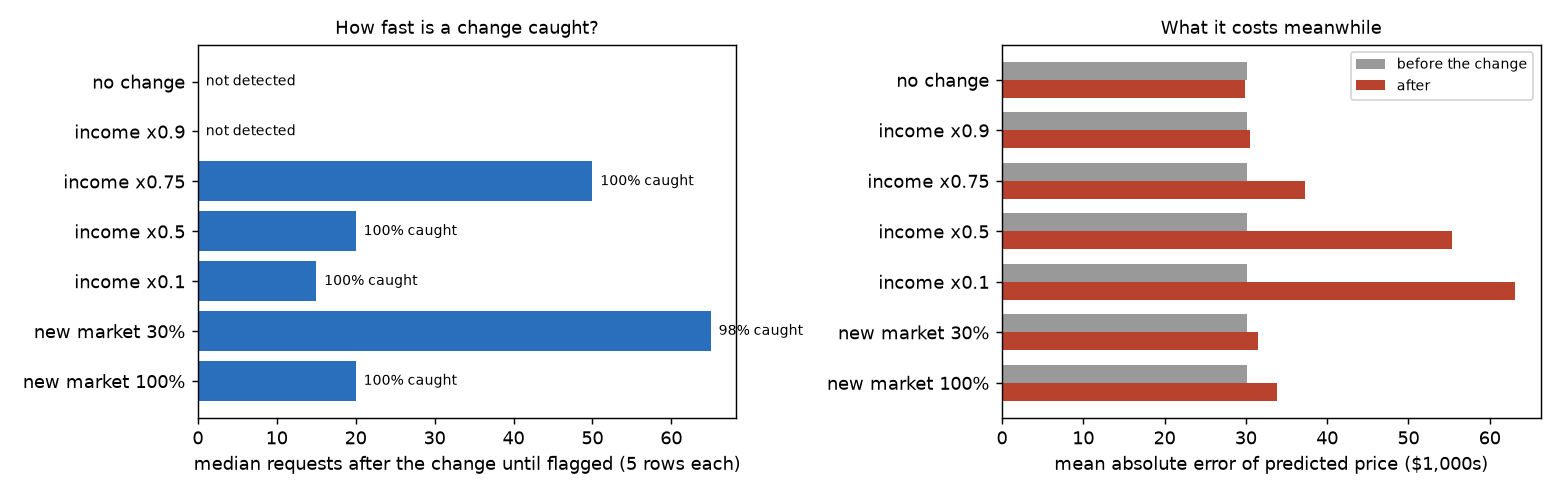

In [6]:
display(Image(str(FIGURES / "drift_experiment.png")))

- **Harmful changes are caught quickly**: income at half or a tenth of its value, within 15 to 20 requests;
  a 25% error within 50. Meanwhile the typical price error rises from $30k to as much as $63k.
- **A harmless change is ignored**: income 10% low barely moves the error, and the monitor stays quiet.
- **Drift isn't the same as damage**: a partner moving into a new market (the Bay Area) trips the monitor, yet the
  model's error rises only 12%. The alert is a reason to look, not proof the model is wrong.
- **False alarms are real**: 7.5% of runs raised an alarm before anything changed. Tuning the warm-up and threshold
  trades false alarms against speed.

## 5. On AWS

The same eight steps run against the deployed stack with `python -m pgw demo-aws`, plus a sign-in page for partner
staff where each person sees only their own partner's usage and data health. Deployment needs an AWS login; the
results will be added here after the first run.